In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

In [2]:
df = pd.read_csv("/content/dengue_synthetic_educational_dataset.csv")
df.head()

,Age_years,Fever,Headache,Muscle_Pain,Joint_Pain,Nausea_or_Vomiting,Days_Since_Symptom_Onset,Platelet_Count_cells_per_uL,White_Blood_Cell_Count_cells_per_uL,Hematocrit_percent,Dengue_Fever
0,9,1,1,0,0,0,6,280733,7098,41.3,1
1,70,1,0,1,1,0,5,201704,4683,36.4,0
2,59,0,1,1,0,0,7,352537,8258,38.8,0
3,40,0,1,0,1,1,1,294811,8655,34.7,0
4,39,1,1,0,0,0,7,145558,5821,32.7,1


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Age_years                            5000 non-null   int64  
 1   Fever                                5000 non-null   int64  
 2   Headache                             5000 non-null   int64  
 3   Muscle_Pain                          5000 non-null   int64  
 4   Joint_Pain                           5000 non-null   int64  
 5   Nausea_or_Vomiting                   5000 non-null   int64  
 6   Days_Since_Symptom_Onset             5000 non-null   int64  
 7   Platelet_Count_cells_per_uL          5000 non-null   int64  
 8   White_Blood_Cell_Count_cells_per_uL  5000 non-null   int64  
 9   Hematocrit_percent                   5000 non-null   float64
 10  Dengue_Fever                         5000 non-null   int64  
dtypes: float64(1), int64(10)
memor

In [4]:
df.describe()

,Age_years,Fever,Headache,Muscle_Pain,Joint_Pain,Nausea_or_Vomiting,Days_Since_Symptom_Onset,Platelet_Count_cells_per_uL,White_Blood_Cell_Count_cells_per_uL,Hematocrit_percent,Dengue_Fever
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,45.377400,0.734200,0.573800,0.539400,0.493600,0.283000,5.519600,194642.962400,6369.179800,40.967760,0.506800
std,26.048813,0.441802,0.494573,0.498495,0.500009,0.450501,2.860638,64696.262905,2080.767032,4.418192,0.500004
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,39534.000000,1000.000000,27.400000,0.000000
25%,23.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,143362.500000,4871.000000,37.900000,0.000000
50%,45.000000,1.000000,1.000000,1.000000,0.000000,0.000000,5.000000,185374.500000,6242.500000,40.700000,1.000000
75%,68.000000,1.000000,1.000000,1.000000,1.000000,1.000000,8.000000,244807.250000,7774.000000,43.800000,1.000000
max,90.000000,1.000000,1.000000,1.000000,1.000000,1.000000,10.000000,471638.000000,14242.000000,58.100000,1.000000


In [5]:
df.shape

(5000, 11)

In [6]:
df.dtypes

,0
Age_years,int64
Fever,int64
Headache,int64
Muscle_Pain,int64
Joint_Pain,int64
Nausea_or_Vomiting,int64
Days_Since_Symptom_Onset,int64
Platelet_Count_cells_per_uL,int64
White_Blood_Cell_Count_cells_per_uL,int64
Hematocrit_percent,float64


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

,0
Age_years,0
Fever,0
Headache,0
Muscle_Pain,0
Joint_Pain,0
Nausea_or_Vomiting,0
Days_Since_Symptom_Onset,0
Platelet_Count_cells_per_uL,0
White_Blood_Cell_Count_cells_per_uL,0
Hematocrit_percent,0


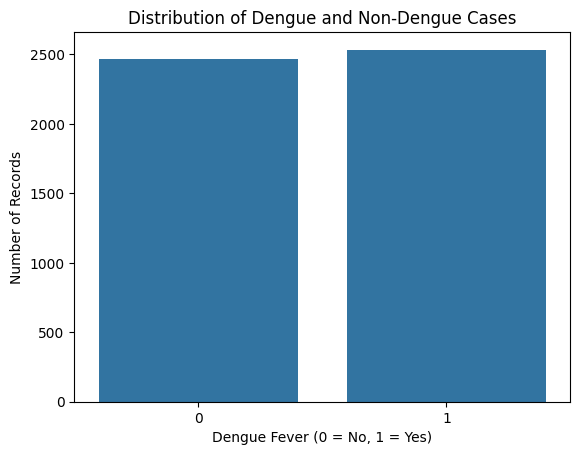

In [9]:
sns.countplot(data=df, x='Dengue_Fever')
plt.title('Distribution of Dengue and Non-Dengue Cases')
plt.xlabel('Dengue Fever (0 = No, 1 = Yes)')
plt.ylabel('Number of Records')
plt.show()

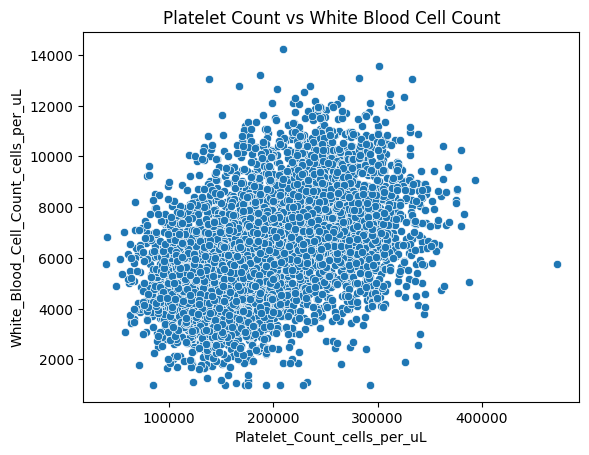

In [10]:
sns.scatterplot(
    x="Platelet_Count_cells_per_uL",
    y="White_Blood_Cell_Count_cells_per_uL",
    data=df)
plt.title("Platelet Count vs White Blood Cell Count")
plt.xlabel("Platelet_Count_cells_per_uL")
plt.ylabel("White_Blood_Cell_Count_cells_per_uL")
plt.show()

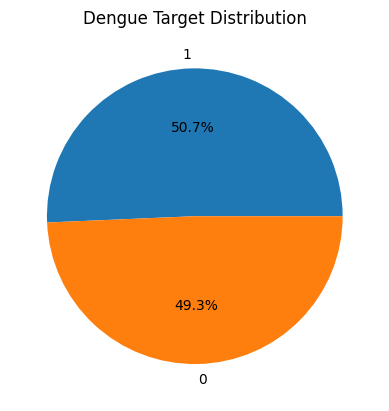

In [23]:
counts = df["Dengue_Fever"].value_counts()
plt.pie(counts,labels=counts.index,autopct="%1.1f%%")
plt.title("Dengue Target Distribution")
plt.show()

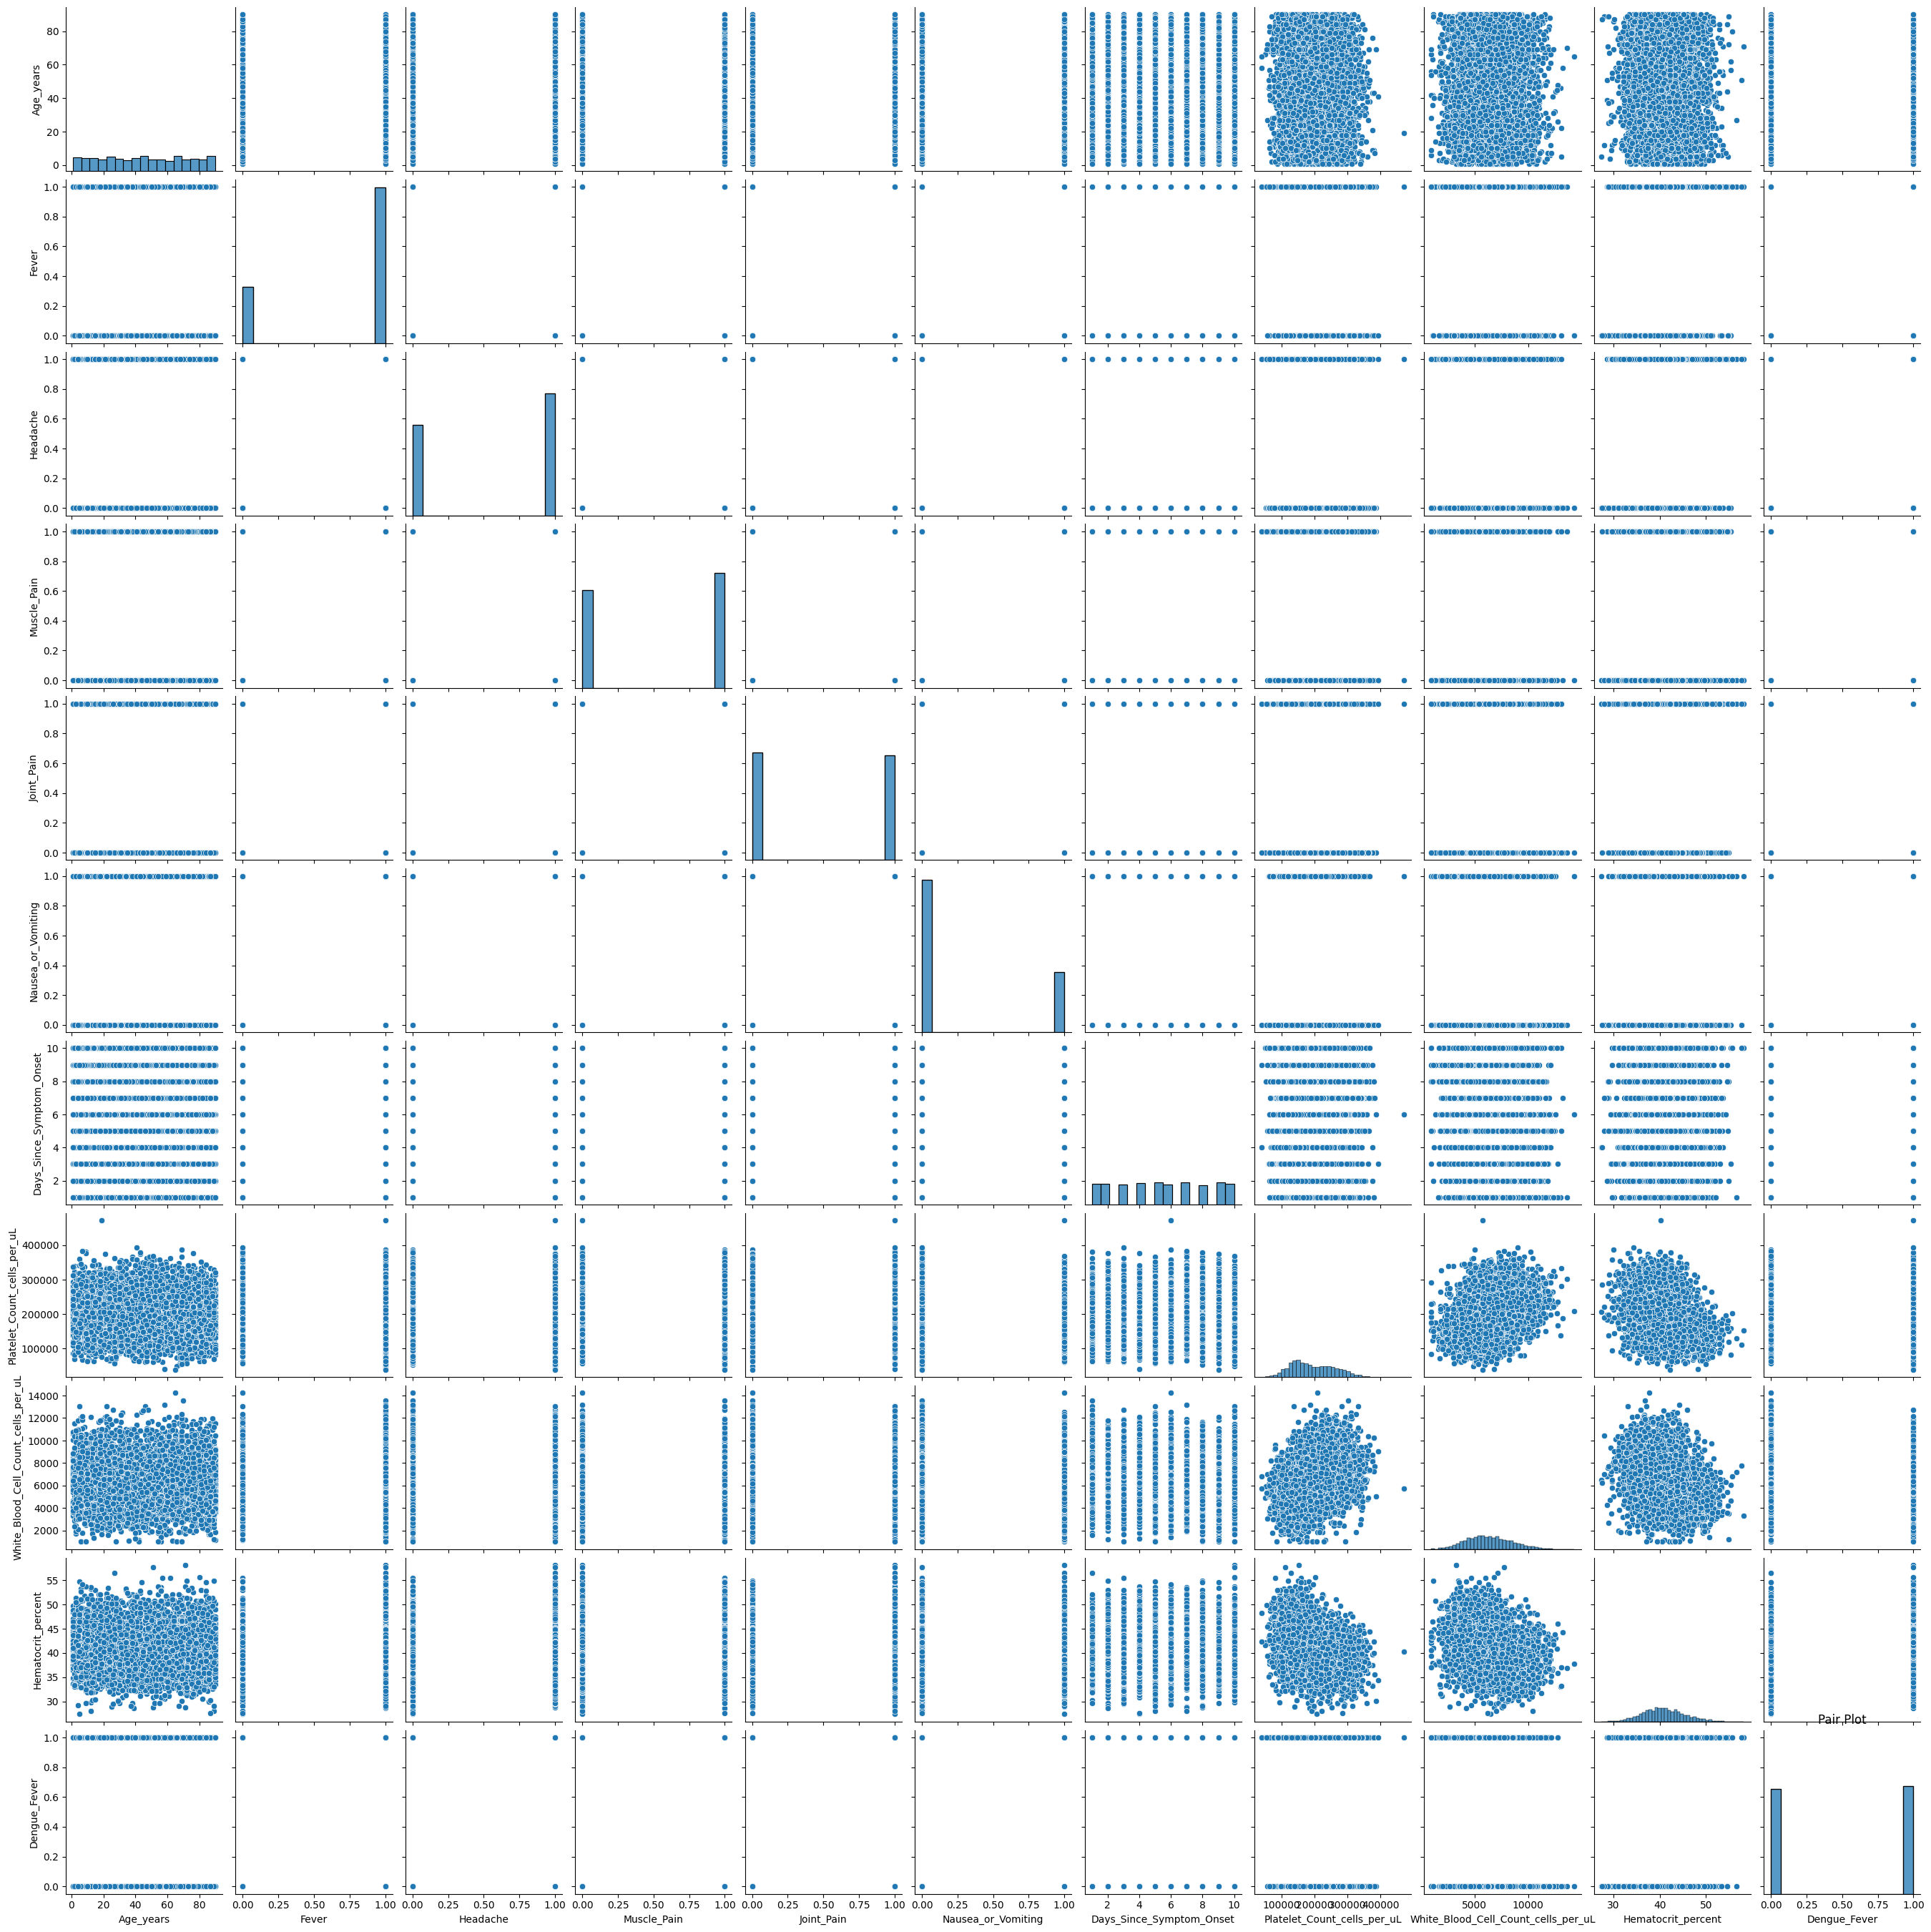

In [12]:
sns.pairplot(df)
plt.title("Pair Plot")
plt.show()

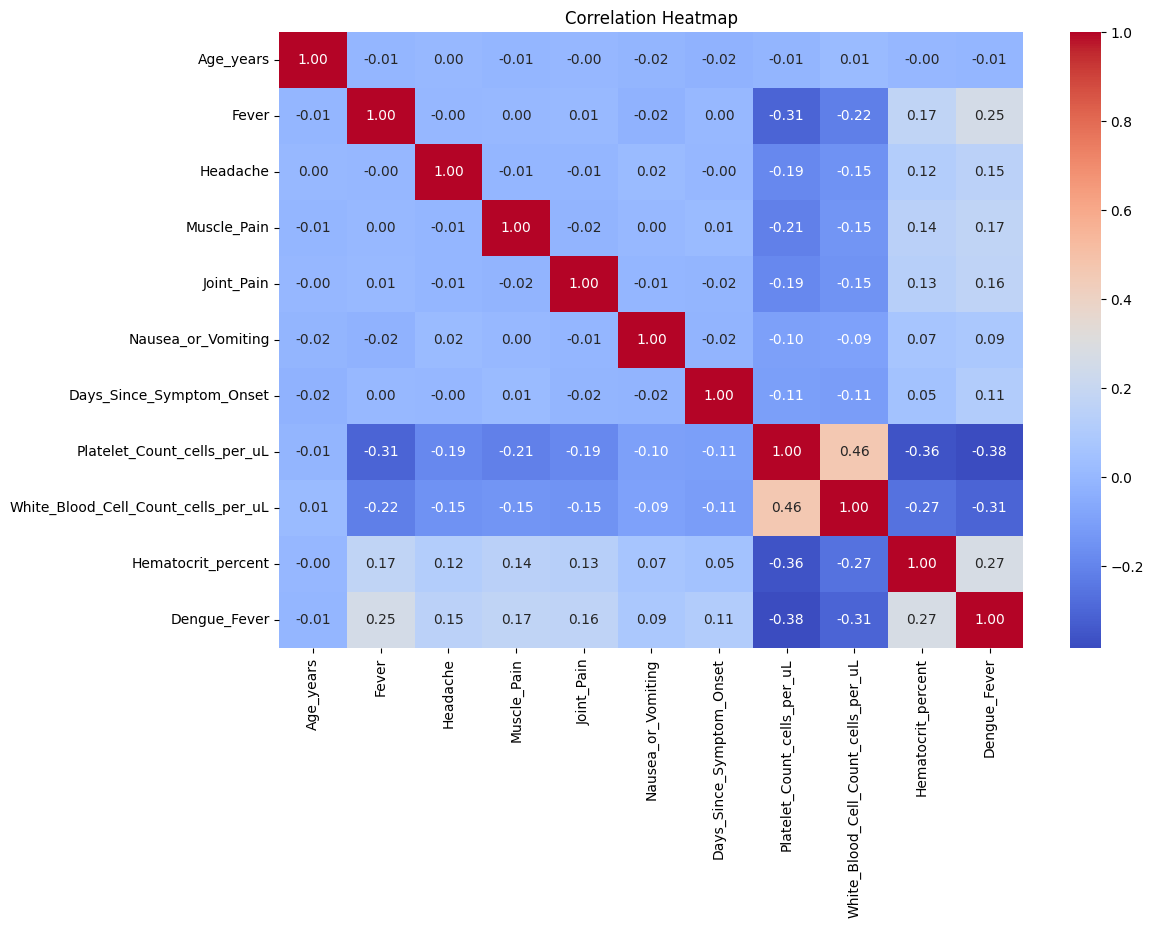

In [13]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [14]:
X = df.iloc[:,:-1]
Y = df.iloc[:,-1]

In [15]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.25, random_state=0)

In [16]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
scaler.fit(X_train)
X_train=scaler.transform(X_train)
X_test=scaler.transform(X_test)
X_test

array([[-0.74929522,  0.60672385, -1.15290613, ..., -0.74113048,
        -0.98411653,  0.58437606],
       [ 0.56271232,  0.60672385,  0.8673733 , ..., -0.48229212,
        -1.33931327,  1.31150588],
       [-1.25094517,  0.60672385,  0.8673733 , ..., -1.42617626,
         0.49377289, -0.61993271],
       ...,
       [ 1.14153917,  0.60672385, -1.15290613, ..., -1.46393286,
        -0.23404168,  1.19789185],
       [ 1.10295072,  0.60672385,  0.8673733 , ..., -0.67909957,
         0.65007881,  1.17516904],
       [ 1.10295072, -1.6481963 ,  0.8673733 , ..., -0.44353053,
        -0.45470886, -0.46087306]])

In [17]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=1)
rf_model.fit(X_train, Y_train)

RandomForestClassifier(random_state=1)

In [18]:
rf_pred = rf_model.predict(X_test)

In [19]:
print("Actual:", Y_test.values.tolist())
print("Predict:", rf_pred.tolist())
print("Accuracy:", accuracy_score(Y_test, rf_pred))

Actual: [1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0

In [20]:
print(classification_report(Y_test,rf_pred))

              precision    recall  f1-score   support

           0       0.71      0.75      0.73       599
           1       0.75      0.71      0.73       651

    accuracy                           0.73      1250
   macro avg       0.73      0.73      0.73      1250
weighted avg       0.73      0.73      0.73      1250



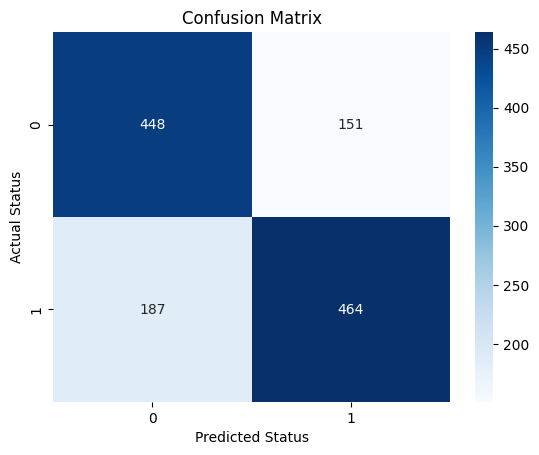

In [21]:
cm = confusion_matrix(Y_test, rf_pred, labels=rf_model.classes_)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=rf_model.classes_,
    yticklabels=rf_model.classes_
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Status")
plt.ylabel("Actual Status")
plt.show()

In [22]:
new_data = [[35, 0, 1, 0, 1, 0, 5, 120000, 6500, 38.5]]
new_data_scaled = scaler.transform(new_data)
prediction = rf_model.predict(new_data_scaled)
print(prediction)

[0]


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
